# Phase 4 — multi-agent investigation

Does splitting the investigation into specialised roles add answer quality beyond the
frozen retriever R = D3 and the Phase 3 single agent, and at what cost? Everything here was
preregistered (`PREREGISTRATION.md` Phase 4, amendments A4 to A6, and the Phase 4 freeze)
before any `dev` output existed.

**The system** is a LangGraph `StateGraph` over the same D3 backend, with four roles:

- **Planner** (`planner_v1`): one or two requirements, the facts that must be found.
- **Researchers** (`researcher_v1`), one per requirement: each sees the whole candidate
  pool, accepts the paragraphs that support its requirement, and may propose the next
  query. Search 1 is the question itself (R's top 10); later searches add 5 unseen
  paragraphs each.
- **Verifier** (`verifier_v2`, under the A4.1 contract): judges each requirement against
  the accepted paragraphs only. When one is unsupported, it names a corrective
  requirement and query; one corrective search, researcher and **recheck** follow.
- **Synthesizer**: the frozen `answer_v2` answer call over the **accepted** paragraphs only.

**Budget:** at most 3 searches, 20 paragraphs and 7 LLM calls per question.

**Before `dev`, the verifier was calibrated on fresh training questions** (A5):
- two subsets of `eda`, C1 and C2, with probes using hand-corrected requirements and
  controlled gold evidence;
- one prompt revision (`verifier_v3`) was tried on C2 and rejected under the frozen keep
  rule, so the system runs with `verifier_v2`.

**Results files.** All five systems compared here are cache-only reproductions at a
single clean commit. Each reproduction aborts on any cache miss or any change in
searches, contexts, call keys or answers.

In [1]:
import collections
import json

import matplotlib.pyplot as plt
import numpy as np

import data
import manifest
import metrics
import scoring

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6})


def read_jsonl(path):
    with open(path) as f:
        return [json.loads(line) for line in f]


def fmt(r):
    return f"{r['delta']:+.3f} [{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]"


dev = data.load_split("dev")
qd = {q.qid: q for q in dev}
corpus = data.corpus()
key = lambda d: (corpus[d].title, corpus[d].text_hash)
has_both = lambda ids, q: set(qd[q].gold) <= {key(d) for d in ids}

runs = {"BM25 K=10": "bm25_k10_p4replay", "R = D3 K=10": "d3_k10_p4replay", "D3 K=16 (matched)": "d3_k16_p4replay",
        "single agent": "agent_single_p4replay", "multi-agent": "multi_agent_p4replay"}
mans = {n: json.load(open(f"results/dev/{f}.jsonl.manifest.json")) for n, f in runs.items()}
SHARED = ["answer_prompt_hash", "schema_hash", "answer_validator_hash", "system_prompt_hash", "renderer_hash"]
for n in list(runs)[:-1]:
    manifest.check_comparable(mans["multi-agent"], mans[n], shared=SHARED, final=True)
recs = {n: {r["qid"]: r for r in read_jsonl(f"results/dev/{f}.jsonl")} for n, f in runs.items()}
sc = {n: {q: scoring.score(qd[q], r) for q, r in recs[n].items()} for n in runs}
ma = recs["multi-agent"]
code = mans["multi-agent"]["comparison_invariants"]["code"]
print(f"5 systems x {len(ma)} dev questions; all from commit {code['commit'][:7]} (dirty: {code['dirty']}); "
      f"verifier {mans['multi-agent']['system_config']['verifier']}")

5 systems x 100 dev questions; all from commit 2982b53 (dirty: False); verifier v2


## 1. Choosing the verifier on training data (A5 and A6)

The format check on 20 `eda` questions passed only after an interface repair (A4.1):
- code computes the aggregate `sufficient` itself;
- references on unsupported requirements are ignored.

A behavioural calibration followed on two fresh `eda` subsets of 20 questions each, C1
and C2. In each subset, two **probes** per question isolate the verifier from planning
and selection errors. Both use requirements corrected by hand against the training
labels:
- **S3, complete evidence:** the corrected requirements with both gold paragraphs. The
  probe should judge the evidence sufficient.
- **S4, incomplete evidence:** the same probe with one gold paragraph removed. It should
  judge the evidence not sufficient.

A hard failure (an output the A4.1 contract rejects) counts against both targets.

In [2]:
cal = []
for subset, tag, verifier in (("c1", "base", "v2"), ("c2", "base", "v2"), ("c2", "v3", "v3")):
    pr = read_jsonl(f"results/eda_calib/{subset}_probe_{tag}.jsonl")
    comp = [x for x in pr if x["probe"] == "complete"]
    inc = [x for x in pr if x["probe"] == "incomplete"]
    cal.append({"subset": subset.upper(), "verifier": verifier,
                "S3 sufficient | complete": f"{sum(x['sufficient'] is True for x in comp)}/{len(comp)}",
                "S4 not sufficient | incomplete": f"{sum(x['sufficient'] is False for x in inc)}/{len(inc)}",
                "probe hard failures": f"{sum(bool(x['failure']) for x in pr)}/{len(pr)}",
                "1-entry outputs for 2 requirements": sum(x["failure"] == "one entry per requirement required" for x in pr)})
import pandas as pd
print(pd.DataFrame(cal).to_string(index=False))
print("targets: S3 >= 0.70, S4 >= 0.70")

subset verifier S3 sufficient | complete S4 not sufficient | incomplete probe hard failures  1-entry outputs for 2 requirements
    C1       v2                     6/20                          14/20               13/40                                   3
    C2       v2                     8/20                          12/20               16/40                                   6
    C2       v3                     3/20                           6/20               29/40                                  25
targets: S3 >= 0.70, S4 >= 0.70


**C1 diagnosis.** The verifier was the weakest stage: S3 fell 0.40 short of its target,
against 0.05 for the planner. On complete evidence it typically marked requirement 1
supported and requirement 2 unsupported.

**The C2 test.** The one permitted prompt revision, `verifier_v3`, added:
- the question first;
- labelled requirements with an explicit count;
- a fixed order of work and a final checklist;
- two invented examples.

On fresh C2 data, v3 was worse on all three frozen keep conditions:
- S3 dropped by 0.25;
- S4 dropped by 0.30;
- the pooled hard-failure rate rose from 0.37 to 0.65.

v3 mostly returned a single entry for a two-requirement plan, despite the stated count.
`verifier_v2` was therefore frozen. Even on fresh data it reaches only S3 0.40 and S4
0.60, so it enters `dev` as a known weak component.

## 2. How the system behaves on `dev` (n = 100)

**Logical calls** are the role invocations the frozen graph requires, cache hits
included. **New generations** exclude two kinds of call:
- the 20 `dev_smoke` questions, whose generations were reused (identical call keys);
- calls repeated within one question.

LLM time is the original generation time of each call.

In [3]:
orig = {r["qid"]: r for r in read_jsonl("results/dev/multi_agent.jsonl")}       # the original run: true cache flags
calls = collections.Counter(r["llm_calls"] for r in ma.values())
new = sum(not c["cached"] for r in orig.values() for c in r["calls"])
print(f"logical calls: {sum(r['llm_calls'] for r in ma.values())} (per question {dict(sorted(calls.items()))}); "
      f"new generations in the dev run: {new}")
print(f"searches per question: {dict(sorted(collections.Counter(r['searches'] for r in ma.values()).items()))}; "
      f"largest pool {max(len({d for b in r['batches'] for d in b}) for r in ma.values())} paragraphs; "
      f"mean accepted {np.mean([len(r['accepted']) for r in ma.values()]):.2f}")


def role_table(rows):
    t = {k: [0, 0] for k in ("planner", "researchers", "initial verifier", "recheck")}
    role = {"planner": "planner", "researcher": "researchers", "verifier": "initial verifier", "verifier_recheck": "recheck"}
    err = {"planner_error": "planner", "researcher_error": "researchers", "verifier_error": "initial verifier",
           "recheck_error": "recheck"}
    for r in rows:
        for c in r["calls"]:
            if c["role"] in role:
                t[role[c["role"]]][0] += 1
        for e in r["events"]:
            if e["event"] in err:
                t[err[e["event"]]][1] += 1
    t["verifier combined"] = [t["initial verifier"][0] + t["recheck"][0], t["initial verifier"][1] + t["recheck"][1]]
    return t


print("\nrole failures (contract or schema), dev:")
for k, (n, f) in role_table(ma.values()).items():
    print(f"  {k:18s} {f:3d}/{n:3d} = {f / n:.2f}")
v = collections.Counter(str(e["sufficient"]) for r in ma.values() for e in r["events"] if e["event"] == "verify")
print(f"\nvalid initial verdicts: {sum(v.values())} (sufficient {v['True']}, not sufficient {v['False']})")

logical calls: 619 (per question {4: 1, 5: 39, 7: 60}); new generations in the dev run: 479
searches per question: {1: 2, 2: 44, 3: 54}; largest pool 20 paragraphs; mean accepted 3.69

role failures (contract or schema), dev:
  planner              1/100 = 0.01
  researchers         18/259 = 0.07
  initial verifier    31/100 = 0.31
  recheck             12/ 60 = 0.20
  verifier combined   43/160 = 0.27

valid initial verdicts: 69 (sufficient 9, not sufficient 60)


Three things stand out:
- The verifier is the unreliable role: 27% of its calls fail the A4.1 contract.
- A failed initial verification skips the corrective search.
- Of the valid initial verdicts, 87% (60 of 69) were "not sufficient".

## 3. Answer quality and cost against the earlier systems

All systems share the frozen `answer_v2` interface (asserted above). Differences are
multi-agent minus the other system, paired over the same 100 questions, with 95% bootstrap
intervals.

**"Mean paragraphs in final answer context"** counts what the synthesizer receives. It
is not the amount of text the system reads: the researchers and the verifier see many
more paragraph presentations across the 619 role calls.

In [4]:
def llm_time(r):
    return sum(c["wall_s"] for c in r["calls"]) if "calls" in r else r["llm"]["wall_s"]


rows = []
for n in runs:
    rr = recs[n]
    rows.append({"system": n,
                 "EM": np.mean([sc[n][q]["em"] for q in rr]), "F1": np.mean([sc[n][q]["f1"] for q in rr]),
                 "SP F1": np.mean([sc[n][q]["sp_strict_f1"] for q in rr]),
                 "final-context JR": np.mean([sc[n][q]["ctx_joint_recall"] for q in rr]),
                 "mean paragraphs in final answer context": np.mean([len(r["displayed"]) for r in rr.values()]),
                 "LLM calls / q": np.mean([r.get("llm_calls", 1) for r in rr.values()]),
                 "median LLM time / q (s)": np.median([llm_time(r) for r in rr.values()])})
print(pd.DataFrame(rows).round(3).to_string(index=False))


def paired(m, a, b, qs=None):
    qs = list(sc[a]) if qs is None else qs
    return metrics.paired_bootstrap({q: sc[a][q][m] for q in qs}, {q: sc[b][q][m] for q in qs})


print("\nmulti-agent minus ...        F1                       EM                       final-context JR")
for n in list(runs)[:-1]:
    print(f"  {n:18s}  " + "   ".join(fmt(paired(m, "multi-agent", n)) for m in ("f1", "em", "ctx_joint_recall")))

           system   EM    F1  SP F1  final-context JR  mean paragraphs in final answer context  LLM calls / q  median LLM time / q (s)
        BM25 K=10 0.41 0.525  0.327              0.62                                    10.00           1.00                   20.634
      R = D3 K=10 0.47 0.629  0.453              0.84                                    10.00           1.00                   23.293
D3 K=16 (matched) 0.51 0.628  0.433              0.91                                    16.00           1.00                   34.169
     single agent 0.47 0.609  0.432              0.93                                    15.95           2.75                   73.449
      multi-agent 0.49 0.638  0.454              0.67                                     3.69           6.19                  110.755

multi-agent minus ...        F1                       EM                       final-context JR
  BM25 K=10           +0.113 [+0.015, +0.211]   +0.080 [-0.010, +0.170]   +0.050 [-0.080, +0.

**Answer quality.** The observed F1 was similar to R, the matched control and the single
agent, and no clear difference was detected: every interval contains zero. That does not
establish equivalence or non-inferiority. The only clear F1 difference is the gain over
BM25.

**Gold evidence.** The final answer context holds both gold paragraphs far less often
than for R, the matched control or the single agent (Joint Recall −0.17 to −0.26).

**Cost.** Median LLM time rose to 111 s per question, against 23 s for R and 73 s for the
single agent.

## 4. The evidence funnel

Where is gold evidence gained and lost? Joint Recall (both gold paragraphs present) is
measured at three points:
1. after search 1, which is R's top 10;
2. over the whole search pool;
3. in the accepted paragraphs the synthesizer receives.

D3 first search          JR = 0.84
full search pool         JR = 0.96
final synthesis context  JR = 0.67

both gold paragraphs retrieved in the pool: 96; later searches completed the pair for 12; retrieved but not both retained (selection loss): 29


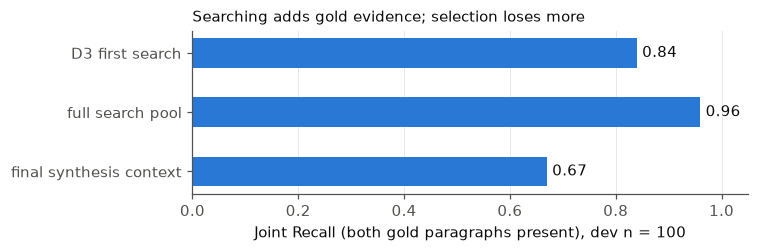

In [5]:
stage = {"D3 first search": lambda r: r["batches"][0],
         "full search pool": lambda r: [d for b in r["batches"] for d in b],
         "final synthesis context": lambda r: r["accepted"]}
funnel = {s: np.mean([has_both(f(ma[q]), q) for q in ma]) for s, f in stage.items()}
for s, v in funnel.items():
    print(f"{s:24s} JR = {v:.2f}")
pool_both = [q for q in ma if has_both(stage["full search pool"](ma[q]), q)]
lost = [q for q in pool_both if not has_both(ma[q]["accepted"], q)]
gained = [q for q in ma if has_both(stage["full search pool"](ma[q]), q) and not has_both(ma[q]["batches"][0], q)]
print(f"\nboth gold paragraphs retrieved in the pool: {len(pool_both)}; later searches completed the pair for {len(gained)}; "
      f"retrieved but not both retained (selection loss): {len(lost)}")

fig, ax = plt.subplots(figsize=(7, 2.4))
names = list(funnel)[::-1]
ax.barh(names, [funnel[s] for s in names], color=BLUE, height=0.5)
for i, s in enumerate(names):
    ax.text(funnel[s] + 0.01, i, f"{funnel[s]:.2f}", va="center", color=INK)
ax.set_xlim(0, 1.05)
ax.set_xlabel("Joint Recall (both gold paragraphs present), dev n = 100")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
ax.set_title("Searching adds gold evidence; selection loses more", loc="left", color=INK, fontsize=10)
plt.tight_layout()
plt.show()

**Searching worked.** The later searches raised availability from 0.84 to 0.96: 12
questions gained the missing paragraph.

**Selection lost more than searching gained.** In 29 of the 96 questions whose pool
held both gold paragraphs, the researchers did not retain both. These 29
**selection-loss** questions are the main error population analysed in section 6.

## 5. The preregistered Phase 4 hypotheses (exploratory, `dev`, n = 100)

**Measures.** Quality differences get 95% paired bootstrap intervals. Behavioural shares
and the latency ratio are raw, as preregistered.

**H4-3 and H4-5 use a proxy.** Gold paragraphs missing from a context are a proxy for
missing support, not proof of it. Alternative evidence, incomplete annotations, model
knowledge or guessing can explain some answers.

**The first verification** is the first verifier call: a valid verdict or an error. Its
evidence is the set of paragraphs that call displayed.

In [6]:
first = {}
for q, r in ma.items():
    v = [c for c in r["calls"] if c["role"] == "verifier"]
    ev = [e for e in r["events"] if e["event"] in ("verify", "verifier_error")]
    first[q] = (v[0]["displayed"], ev[0])
corrective_attempt = lambda r: any(e.get("stage") == "corrective" and e["event"] in ("search", "search_skipped") for e in r["events"])

h1_ctx = np.mean([len(r["displayed"]) for r in ma.values()])
h1_jr = np.mean([sc["multi-agent"][q]["ctx_joint_recall"] for q in ma])
h2 = paired("f1", "multi-agent", "single agent")
inc = [q for q, (disp, _) in first.items() if not has_both(disp, q)]
inc_valid = [q for q in inc if first[q][1]["event"] == "verify"]
h3 = sum(not first[q][1]["sufficient"] for q in inc_valid)
comp = [q for q, (disp, _) in first.items() if has_both(disp, q)]
comp_valid = [q for q in comp if first[q][1]["event"] == "verify"]
h4_all, h4_valid = sum(corrective_attempt(ma[q]) for q in comp), sum(corrective_attempt(ma[q]) for q in comp_valid)
h5 = {}
for n in ("multi-agent", "single agent"):
    lack = [q for q in recs[n] if not has_both(recs[n][q]["displayed"], q)]
    h5[n] = (sum(bool(recs[n][q]["output"]["supported"]) for q in lack), len(lack))
t = {n: np.median([llm_time(r) for r in recs[n].values()]) for n in ("multi-agent", "single agent")}

H = [("H4-1", f"final context {h1_ctx:.2f} paragraphs (< 15.95) and JR {h1_jr:.2f} (>= 0.81); vs R {fmt(paired('ctx_joint_recall', 'multi-agent', 'R = D3 K=10'))}",
      "fails (context smaller, but JR below 0.81)"),
     ("H4-2", f"multi - single F1 {fmt(h2)}", "holds on its point-estimate criterion (> 0); the difference is not statistically established"),
     ("H4-3", f"first verification lacking a gold paragraph: {len(inc)} ({len(inc) - len(inc_valid)} verifier errors); "
              f"not sufficient {h3}/{len(inc_valid)} = {h3 / len(inc_valid):.2f} (>= 0.60)", "holds"),
     ("H4-4", f"both gold at first verification: {len(comp)}; corrective search {h4_all}/{len(comp)} = {h4_all / len(comp):.2f} "
              f"({len(comp) - len(comp_valid)} verifier errors cannot trigger one); among valid verdicts "
              f"{h4_valid}/{len(comp_valid)} = {h4_valid / len(comp_valid):.2f} (<= 0.40)", "fails"),
     ("H4-5", f"final context lacking a gold paragraph, self-reported supported = true: multi {h5['multi-agent'][0]}/{h5['multi-agent'][1]} = "
              f"{h5['multi-agent'][0] / h5['multi-agent'][1]:.2f}; single {h5['single agent'][0]}/{h5['single agent'][1]} = "
              f"{h5['single agent'][0] / h5['single agent'][1]:.2f}", "fails (not lower; the single agent's n is 7)"),
     ("H4-6", f"median LLM time per question {t['multi-agent']:.0f} s vs {t['single agent']:.0f} s, ratio {t['multi-agent'] / t['single agent']:.2f} (>= 1.0)", "holds")]
for h, est, verdict in H:
    print(f"{h}: {est}\n      -> {verdict}")

H4-1: final context 3.69 paragraphs (< 15.95) and JR 0.67 (>= 0.81); vs R -0.170 [-0.270, -0.070]
      -> fails (context smaller, but JR below 0.81)
H4-2: multi - single F1 +0.029 [-0.047, +0.106]
      -> holds on its point-estimate criterion (> 0); the difference is not statistically established
H4-3: first verification lacking a gold paragraph: 45 (12 verifier errors); not sufficient 30/33 = 0.91 (>= 0.60)
      -> holds
H4-4: both gold at first verification: 55; corrective search 30/55 = 0.55 (19 verifier errors cannot trigger one); among valid verdicts 30/36 = 0.83 (<= 0.40)
      -> fails
H4-5: final context lacking a gold paragraph, self-reported supported = true: multi 22/33 = 0.67; single 4/7 = 0.57
      -> fails (not lower; the single agent's n is 7)
H4-6: median LLM time per question 111 s vs 73 s, ratio 1.51 (>= 1.0)
      -> holds


In [7]:
for name, qs in (("both gold displayed", comp_valid), ("a gold paragraph missing", inc_valid)):
    s = sum(first[q][1]["sufficient"] for q in qs)
    print(f"valid first verdicts, {name:24s}: sufficient {s}/{len(qs)} = {s / len(qs):.2f}")

valid first verdicts, both gold displayed     : sufficient 6/36 = 0.17
valid first verdicts, a gold paragraph missing: sufficient 3/33 = 0.09


**H4-3 holds, but mostly through blanket caution.** The verifier judged "sufficient" only
slightly more often when both gold paragraphs were displayed (6/36) than when one was
missing (3/33). It rarely accepts complete evidence, which is also why H4-4 fails: 83% of
valid verdicts on complete gold still asked for a corrective search.

## 6. Error analysis (exploratory, post hoc)

None of these breakdowns was preregistered. They describe where this system gained and
lost, and they do not establish causes.

In [8]:
def mean_f1(n, qs):
    return np.mean([sc[n][q]["f1"] for q in qs]) if qs else float("nan")


complete = [q for q in ma if has_both(ma[q]["accepted"], q)]
incomplete = [q for q in ma if q not in set(complete)]
print("(a) F1 by gold completeness of the multi-agent final context")
for name, qs in (("complete", complete), ("incomplete", incomplete)):
    print(f"    {name:10s} n = {len(qs):3d}  multi F1 {mean_f1('multi-agent', qs):.3f}  (R on the same questions {mean_f1('R = D3 K=10', qs):.3f})")

print(f"\n(b) the {len(lost)} selection-loss questions (both gold retrieved, not both retained)")
d = paired("f1", "multi-agent", "R = D3 K=10", lost)
print(f"    multi F1 {mean_f1('multi-agent', lost):.3f}, R F1 {mean_f1('R = D3 K=10', lost):.3f}, difference {fmt(d)}")
worse = sum(sc["multi-agent"][q]["f1"] < sc["R = D3 K=10"][q]["f1"] for q in lost)
better = sum(sc["multi-agent"][q]["f1"] > sc["R = D3 K=10"][q]["f1"] for q in lost)
print(f"    multi worse on {worse}, better on {better}, equal on {len(lost) - worse - better}")

(a) F1 by gold completeness of the multi-agent final context
    complete   n =  67  multi F1 0.709  (R on the same questions 0.634)
    incomplete n =  33  multi F1 0.494  (R on the same questions 0.618)

(b) the 29 selection-loss questions (both gold retrieved, not both retained)
    multi F1 0.555, R F1 0.696, difference -0.142 [-0.272, -0.030]
    multi worse on 5, better on 1, equal on 23


In [9]:
import hops
ctx = data.load_contexts("dev")
acc_stats = collections.defaultdict(lambda: [0, 0])          # group -> [accepted, retrieved]
for q, r in ma.items():
    pool = {key(d): d for b in r["batches"] for d in b}
    first_search = {key(d) for d in r["batches"][0]}
    accepted = {key(d) for d in r["accepted"]}
    ch = hops.chain(qd[q], ctx[q]) if qd[q].type == "bridge" else None
    for g in qd[q].gold:
        if g not in pool:
            continue
        hop = ("first hop" if g[0] == ch.first else "second hop") if ch is not None and ch.determined else "comparison" if ch is None else "bridge, undetermined"
        for grp in ("all", hop, "in search 1" if g in first_search else "found by a later search"):
            acc_stats[grp][1] += 1
            acc_stats[grp][0] += g in accepted
print("(c) gold paragraphs accepted, given retrieved into the pool")
for grp in ("all", "first hop", "second hop", "bridge, undetermined", "comparison", "in search 1", "found by a later search"):
    a, n = acc_stats[grp]
    print(f"    {grp:24s} {a:3d}/{n:3d} = {a / n:.2f}")

(c) gold paragraphs accepted, given retrieved into the pool
    all                      165/196 = 0.84
    first hop                 66/ 77 = 0.86
    second hop                65/ 77 = 0.84
    bridge, undetermined       2/  2 = 1.00
    comparison                32/ 40 = 0.80
    in search 1              156/182 = 0.86
    found by a later search    9/ 14 = 0.64


In [10]:
valid_q = [q for q in ma if first[q][1]["event"] == "verify"]
error_q = [q for q in ma if first[q][1]["event"] == "verifier_error"]
print("(d) questions by the outcome of the first verification")
for name, qs in (("valid verdict", valid_q), ("verifier error", error_q)):
    jr = np.mean([sc["multi-agent"][q]["ctx_joint_recall"] for q in qs])
    corr = sum(corrective_attempt(ma[q]) for q in qs)
    print(f"    {name:15s} n = {len(qs):3d}  F1 {mean_f1('multi-agent', qs):.3f}  final JR {jr:.2f}  corrective search {corr}")
errs = collections.Counter(first[q][1]["error"] for q in error_q)
print("    first-verification errors:", dict(errs))

print("\n(e) corrective searches")
n_corr = filled = accepted_fill = 0
recheck = collections.Counter()
for q, r in ma.items():
    cs = [e for e in r["events"] if e.get("stage") == "corrective" and e["event"] == "search"]
    if not cs:
        continue
    n_corr += 1
    before = {key(d) for d in first[q][0]}
    missing = set(qd[q].gold) - before
    added = {key(d) for d in cs[0]["added"]}
    if missing & added:
        filled += 1
        accepted_fill += bool(missing & {key(d) for d in r["accepted"]})
    rc = [e for e in r["events"] if e["event"] in ("recheck", "recheck_error")]
    recheck[("error" if rc[0]["event"] == "recheck_error" else "sufficient" if rc[0]["sufficient"] else "not sufficient") if rc else "none"] += 1
print(f"    executed: {n_corr}; added a gold paragraph missing at the first verification: {filled} "
      f"(then accepted: {accepted_fill}); recheck outcomes {dict(recheck)}")

(d) questions by the outcome of the first verification
    valid verdict   n =  69  F1 0.655  final JR 0.70  corrective search 60
    verifier error  n =  31  F1 0.600  final JR 0.61  corrective search 0
    first-verification errors: {'one entry per requirement required': 7, 'invalid reference on a supported requirement': 13, 'corrective_requirement must be an unsupported requirement': 10, 'supported=true requires at least one reference': 1}

(e) corrective searches
    executed: 57; added a gold paragraph missing at the first verification: 4 (then accepted: 3); recheck outcomes {'not sufficient': 42, 'sufficient': 4, 'error': 11}


In [11]:
print("(f) corrective paths whose search was skipped (no new search results), yet the corrective researcher and recheck ran")
for q, r in ma.items():
    skip = [e for e in r["events"] if e["event"] == "search_skipped" and e.get("stage") == "corrective"]
    if not skip:
        continue
    res = {c["stage"]: c for c in r["calls"] if c["role"] == "researcher" and c["requirement"] == skip[0].get("requirement", 2)}
    keys = [c["key"] for c in r["calls"]]
    rc = [e for e in r["events"] if e["event"] in ("recheck", "recheck_error")][0]
    corr_ev = [e for e in r["events"] if e.get("stage") == "corrective" and e["event"] in ("research", "researcher_error")][0]
    print(f"  {q[:8]}  query {skip[0]['query']!r} ({skip[0]['reason']}); repeated call keys {len(keys) - len(set(keys))}; "
          f"corrective researcher saw {len(res['corrective']['candidates'])} candidates (planned: {len(res['planned']['candidates'])}), "
          f"accepted {corr_ev.get('accepted', corr_ev['event'])}; recheck {rc.get('supported', rc['event'])}; F1 {sc['multi-agent'][q]['f1']:.2f}")

(f) corrective paths whose search was skipped (no new search results), yet the corrective researcher and recheck ran
  5ae038e9  query 'birth date of César Cui' (duplicate_query); repeated call keys 0; corrective researcher saw 11 candidates (planned: 13), accepted ['The Prisoner of the Caucasus (poem)', 'Yevgeny Krylatov']; recheck recheck_error; F1 0.57
  5a88651b  query 'number of acts in Agrippina' (duplicate_query); repeated call keys 2; corrective researcher saw 13 candidates (planned: 13), accepted researcher_error; recheck [True, False]; F1 1.00
  5abbd58d  query 'Kansas City Southern headquarters location' (duplicate_query); repeated call keys 2; corrective researcher saw 14 candidates (planned: 14), accepted []; recheck [True, False]; F1 1.00


In [12]:
print("(g) selection-loss questions where the multi-agent answer was worse than R's")
for q in [q for q in lost if sc["multi-agent"][q]["f1"] < sc["R = D3 K=10"][q]["f1"]]:
    r = ma[q]
    dropped = [g[0] for g in qd[q].gold if g not in {key(d) for d in r["accepted"]}]
    print(f"\n  {qd[q].question}\n    gold {qd[q].answer!r}; multi {r['output']['answer']!r}; R {recs['R = D3 K=10'][q]['output']['answer']!r}")
    print(f"    requirements: {r['requirements']}")
    print(f"    accepted: {[corpus[d].title for d in r['accepted']]}; gold dropped: {dropped}")

(g) selection-loss questions where the multi-agent answer was worse than R's

  What year was Playford B Power Station permanently closed in by its Australian operator?
    gold '2015'; multi 'no'; R '2015'
    requirements: ['The year Playford B Power Station was permanently closed.', 'The Australian operator of Playford B Power Station.']
    accepted: ['Dunston Power Station', 'Alinta Energy', 'Blyth Power Station']; gold dropped: ['Playford B Power Station']

  Ambrose Mendy has managed and/or advised a British professional boxer that as of July 2017 is ranked the world's seventh best super middleweight by who?
    gold '"The Ring" magazine'; multi 'no'; R 'The Ring'
    requirements: ['The name of the British professional boxer managed or advised by Ambrose Mendy.', "The organization responsible for ranking boxers, specifically the entity that ranked the mentioned boxer as the world's seventh best super middleweight as of July 2017."]
    accepted: ['Ambrose Mendy']; gold dropped:

In [13]:
yn = lambda s: s.strip().lower().strip(".") in ("yes", "no")
open_q = [q for q in qd if not yn(qd[q].answer)]
print(f"(h) 'yes'/'no' answers to the {len(open_q)} questions whose gold answer is not yes/no")
for n in runs:
    bad = [q for q in open_q if yn(recs[n][q]["output"]["answer"])]
    inc_bad = sum(not has_both(recs[n][q]["displayed"], q) for q in bad)
    print(f"    {n:18s} {len(bad):2d}  (final context missing a gold paragraph: {inc_bad})")

(h) 'yes'/'no' answers to the 94 questions whose gold answer is not yes/no
    BM25 K=10           1  (final context missing a gold paragraph: 0)
    R = D3 K=10         1  (final context missing a gold paragraph: 1)
    D3 K=16 (matched)   2  (final context missing a gold paragraph: 0)
    single agent        1  (final context missing a gold paragraph: 0)
    multi-agent         4  (final context missing a gold paragraph: 3)


**What the breakdowns show** (all exploratory):

- **Higher F1 was associated with retaining both gold paragraphs; lower F1 was associated
  with selection loss.** These post hoc groups do not establish causation.
  - Complete final context, 67 questions: multi-agent F1 0.709 against R's 0.634 on the
    same questions. This is consistent with the distraction effect seen in Phase 3.
  - The 29 selection-loss questions: F1 −0.14 [−0.27, −0.03] against R. That difference
    comes from a few questions: 5 worse, 1 better, 23 equal.
- **Selection drops about one retrieved gold paragraph in six** (165/196 accepted).
  - The rate is similar for first-hop, second-hop and comparison paragraphs.
  - It is worse for paragraphs found by a later search (9/14).
  - In the examples, the researcher accepted a related entity's paragraph and missed the
    entity the question names: Dunston Power Station instead of Playford B, or the
    manager instead of the boxer.
  - The synthesizer then sometimes falls back to a bare "no" for an open question. The
    multi-agent system gave 4 such answers, against 1–2 for the other systems; 3 of the 4
    lacked a gold paragraph.
- **Corrective searches rarely repair anything.**
  - 57 were executed, but only 4 added a gold paragraph missing at the first verification.
  - Among the 57 executed corrective-search paths: 42 rechecks remained insufficient, 4
    became sufficient, and 11 failed.
  - The three skipped corrective searches produced two repeated insufficient verdicts and
    one recheck error. That gives 60 rechecks in total: 48 valid and 12 failures.
  - Most corrective searches follow the verifier's caution, not a real gap.
- **Verifier errors skip correction.**
  - The 31 questions whose first verification failed got no corrective search.
  - Their F1 (0.600) was close to the valid-verdict questions' (0.655).
- **Paths with no new search results.**
  - In three questions the corrective search was skipped as a duplicate query, and the
    corrective researcher and the recheck still ran.
  - In two of them, both calls repeated earlier calls exactly, so they added nothing.
  - In the third, the corrective researcher re-read the remaining unaccepted pool and
    accepted two more (non-gold) paragraphs, and the recheck then failed.

## 7. Phase 4 summary

| `dev`, n = 100 | R = D3 K = 10 | D3 K = 16 (matched) | Single agent | Multi-agent |
|---|---|---|---|---|
| Answer F1 | 0.629 | 0.628 | 0.609 | 0.638 |
| Final-context Joint Recall | 0.84 | 0.91 | **0.93** | 0.67 |
| Mean paragraphs in final answer context | 10 | 16 | 15.95 | **3.69** |
| LLM calls per question (logical) | 1 | 1 | 2.75 | 6.19 |
| Median LLM time per question | 23 s | 34 s | 73 s | 111 s |

**The multi-agent pipeline compressed the final answer context from 10–16 paragraphs to
3.69, but the compression was unsafe: Joint Recall fell to 0.67.** No answer-quality
improvement over D3 RAG or the single agent was established, while median LLM time
increased to 111 seconds.

- **Retrieval was not the bottleneck.** Searching raised evidence availability from
  0.84 to 0.96.
- **Researcher selection lost more than searching gained.** 29 questions had both gold
  paragraphs retrieved but not retained.
- **The verifier is the weakest role.**
  - 27% of its calls failed the contract.
  - It judged nearly everything insufficient, whether or not the gold was complete.
  - Its corrective searches rarely added missing evidence.
- **Hypotheses:**
  - H4-3 and H4-6 hold.
  - H4-2 holds only on its point-estimate criterion; the difference is not statistically
    established.
  - H4-1, H4-4 and H4-5 fail.

These results apply to the frozen system: this 7B model, these prompts and this budget.